# CMSC 320 (Checkpoint 2): County-Level Data Cleaning & Aggregation

Combine 2023 BLS, poverty/income, and education data sources into a single row per county/county-equivalent, using FIPS (state-national) identifiers. Running all five code cells writes `county_aggregated_2023.csv` which represents the aggregated dataset we will use for analysis.

IMPORTANT: FIPS should be treated as the unique identifier for counties. All data is for 2023 but education source is filtered for data where lvl is received 2019–2023. All data is county-level but the raw sources contain aggregated-lvl entries which are filtered out.

Interestingly, education does contain counts for four mutually exclusive adult educational groups. I found the sum of the population aged 25 and older for the 2019–2023 period across all educations, which is included as `population_25_plus_2019_2023` but is still not a total pop. That can be found in `population_2023`. I also included the pops for the education groups but not sure how useful it will be.

#### BLS 2023

In [144]:
import pandas as pd

In [145]:
bls = pd.read_excel("data/BLS_County_Labor_Force_2023.xlsx", sheet_name="laucnty23", skiprows=1, dtype=str)
print(f"{bls.shape[0]} rows")
bls = bls[bls["Year"] == "2023"]

# Get full FIPS code
bls["fips"] = bls["State FIPS Code"].str.zfill(2) + bls["County FIPS Code"].str.zfill(3)

# Select what we need with less generic non-whitespace names
new_cols = {
    "County Name/State Abbreviation": "county_name",
    "Labor Force": "labor_force_2023",
    "Employed": "employed_2023",
    "Unemployed": "unemployed_2023",
    "Unemployment Rate (%)": "unemployment_rate_2023"
}
bls = bls[[
    "fips",
    "County Name/State Abbreviation",
    "Labor Force",
    "Employed",
    "Unemployed",
    "Unemployment Rate (%)"
    ]].rename(columns=new_cols)

# Make sure to parse
bls_numbers = ["labor_force_2023", "employed_2023", "unemployed_2023", "unemployment_rate_2023"]
bls[bls_numbers] = bls[bls_numbers].apply(pd.to_numeric)
display(bls.head())

3224 rows


,fips,county_name,labor_force_2023,employed_2023,unemployed_2023,unemployment_rate_2023
0,01001,"Autauga County, AL",27823,27227,596,2.1
1,01003,"Baldwin County, AL",113708,111245,2463,2.2
2,01005,"Barbour County, AL",8703,8362,341,3.9
3,01007,"Bibb County, AL",8617,8409,208,2.4
4,01009,"Blount County, AL",26568,26026,542,2.0


#### Poverty 2023

Note: the CSV is formatted so each county has separate `Attribute`/`Value` rows, so we select the needed attributes and put them into a column-friendly format so that there is one row per FIPS code. Also we have a rucc score which is nice.

In [146]:
poverty = pd.read_csv("data/Poverty2023.csv", dtype={"FIPS_Code": str})  # Keep fips as strs

# Get the needed attrs, fix up data to aggregate the multiple rows/county into one
# Attrs are available w/ a value which tells us the county's poverty_rate for example
poverty_names = {
    "PCTPOVALL_2023": "poverty_rate_2023",
    "PCTPOV017_2023": "child_poverty_rate_2023",
    "MEDHHINC_2023": "median_household_income_2023",
    "Rural_Urban_Continuum_Code_2023": "rural_urban_continuum_code_2023"
}
poverty = poverty[poverty["Attribute"].isin(poverty_names)]
poverty["fips"] = poverty["FIPS_Code"].str.zfill(5)
# ending "000" means aggregate totals, we want only individual county-level records
poverty = poverty[poverty["fips"].str[-3:] != "000"]
poverty = poverty.pivot(index="fips", columns="Attribute", values="Value").reset_index()
poverty = poverty.rename(columns=poverty_names)

print("Education conversion/missing values:", poverty.isna().sum())  # Should be minimal
print("Poverty/income county records:", len(poverty))    # Should be about 3144
print("Duplicate FIPS:", poverty["fips"].duplicated().sum())

Education conversion/missing values: Attribute
fips                               0
median_household_income_2023       1
child_poverty_rate_2023            1
poverty_rate_2023                  1
rural_urban_continuum_code_2023    0
dtype: int64
Poverty/income county records: 3144
Duplicate FIPS: 0


#### Education 2023 and 25+ adult population
Note: I figured we can use the numbers here to find 25+ aged pop which might be nice since it could go hand-in-hand with employment (entering the workforce age)

So `population_25_plus_2019_2023` is the 25+ aged adults in the county that got their education 2019-2023

In [147]:
education = pd.read_csv("data/Education2023.csv", encoding="latin1", dtype={"FIPS Code": str})  # latin1 encoding

population_attributes = [
    "Less than high school graduate, 2019-23",
    "High school graduate (or equivalency), 2019-23",
    "Some college or associate degree, 2019-23",
    "Bachelor's degree or higher, 2019-23"
]
bachelors_attribute = "Percent of adults with a bachelor's degree or higher, 2019-23"

education = education[education["Attribute"].isin(population_attributes + [bachelors_attribute])]
education["fips"] = education["FIPS Code"].str.zfill(5)
education = education[education["fips"].str[-3:] != "000"]   # Keep only county-level (these are state/country-level)

# Fix the multiple row problem again
education = education.pivot(index="fips", columns="Attribute", values="Value").reset_index()
education_columns = population_attributes + [bachelors_attribute] # We want all lvls together
education[education_columns] = education[education_columns].apply(pd.to_numeric)

print("Education conversion/missing values:", education.isna().sum())  # Should be minimal

education["population_25_plus_2019_2023"] = education[population_attributes].sum(axis=1)
education = education[
    ["fips", "population_25_plus_2019_2023", bachelors_attribute] + population_attributes].rename(
    columns={bachelors_attribute: "bachelors_pct_2019_2023"})
print("Education county records:", len(education))   # Ideally close to 3144
print("Duplicate FIPS:", education["fips"].duplicated().sum())

Education conversion/missing values: Attribute
fips                                                             0
Bachelor's degree or higher, 2019-23                             0
High school graduate (or equivalency), 2019-23                   0
Less than high school graduate, 2019-23                          0
Percent of adults with a bachelor's degree or higher, 2019-23    0
Some college or associate degree, 2019-23                        0
dtype: int64
Education county records: 3222
Duplicate FIPS: 0


#### Population 2023
Straightforward, we find the county-lvl population

In [148]:
population = pd.read_csv("data/PopulationEstimates2023.csv", encoding="latin1", dtype={"FIPStxt": str})

# Filter for county-lvl and correct attr
population["fips"] = population["FIPStxt"].str.zfill(5)
population = population[
    (population["Attribute"] == "POP_ESTIMATE_2023") &
    (population["fips"].str[-3:] != "000")
][["fips", "Value"]]

population = population.rename(columns={"Value": "population_2023"})
population["population_2023"] = population["population_2023"].astype(int)

print("Population county records:", len(population)) # Should be close to 3144
print("Duplicate FIPS:", population["fips"].duplicated().sum())

Population county records: 3222
Duplicate FIPS: 0


#### Merging the three dataframes

In [149]:
# Conduct inner joins on the three sources, remove na
bls_poverty = bls.merge(poverty, on="fips", how="inner", validate="one_to_one")
county = bls_poverty.merge(education, on="fips", how="inner", validate="one_to_one")
county = county.merge(population, on="fips", how="inner", validate="one_to_one")

# Should be minimial
print("FIPS lost after poverty merge:", len(set(bls["fips"]) - set(bls_poverty["fips"])))
print("FIPS lost after education merge:", len(set(bls_poverty["fips"]) - set(county["fips"])))

FIPS lost after poverty merge: 78
FIPS lost after education merge: 0


#### Export

In [150]:
# Assert correct types
count_columns = ["population_25_plus_2019_2023", "labor_force_2023", "employed_2023",
                 "unemployed_2023", "median_household_income_2023", "rural_urban_continuum_code_2023"]
county[count_columns] = county[count_columns].astype(int)
percent_columns = ["unemployment_rate_2023", "poverty_rate_2023", "child_poverty_rate_2023", "bachelors_pct_2019_2023"]

print("Duplicate FIPS:", county["fips"].duplicated().sum()) # Should be 0 by now
print("Missing values:\n", county.isna().sum())

# Summary stats of the data
print("Data types:\n", county.dtypes)
print("Summary statistics:\n", county.describe())

county.to_csv("county_aggregated_2023.csv", index=False)
print("Aggregate dataset in county_aggregated_2023.csv")

Duplicate FIPS: 0
Missing values:
 fips                                              0
county_name                                       0
labor_force_2023                                  0
employed_2023                                     0
unemployed_2023                                   0
unemployment_rate_2023                            0
median_household_income_2023                      0
child_poverty_rate_2023                           0
poverty_rate_2023                                 0
rural_urban_continuum_code_2023                   0
population_25_plus_2019_2023                      0
bachelors_pct_2019_2023                           0
Less than high school graduate, 2019-23           0
High school graduate (or equivalency), 2019-23    0
Some college or associate degree, 2019-23         0
Bachelor's degree or higher, 2019-23              0
population_2023                                   0
dtype: int64
Data types:
 fips                                                  s

In [151]:
# Python libraries used in this tutorial

import pandas as pd                 
import matplotlib.pyplot as plt     # Used to label and format the graph
import seaborn as sns               # Used to create the scatterplot and linear trend line
from scipy.stats import pearsonr    # Used to calculate the Pearson correlation and p-value

## Relationship Between County Poverty and Unemployment

### Research question

Is a county's poverty rate related to its unemployment rate in 2023?

Poverty and unemployment are two important measures of a county's economic condition. Examining their relationship can help us understand whether counties with higher poverty rates also tend to experience higher unemployment rates.

For this analysis, we use the 2023 poverty and unemployment rates from our combined dataset.

In [152]:
poverty = county["poverty_rate_2023"]
unemployment = county["unemployment_rate_2023"]
county[
    ["poverty_rate_2023", "unemployment_rate_2023"]
].describe()

,poverty_rate_2023,unemployment_rate_2023
count,3143.000000,3143.000000
mean,14.491569,3.616067
std,5.552983,1.187426
min,3.300000,1.300000
25%,10.600000,2.900000
50%,13.600000,3.400000
75%,17.400000,4.200000
max,49.600000,17.600000


### Basic characteristics of the variables

Across the 3,143 counties, the average poverty rate was 14.49% and the average unemployment rate was 3.62%. Poverty rates ranged from 3.3% to 49.6%, while unemployment rates ranged from 1.3% to 17.6%, suggesting that the dataset contains several counties with unusually high values.

### Statistical method

We use a Pearson correlation test because poverty rate and unemployment rate are both quantitative numerical variables measured as percentages. Pearson correlation measures the direction and strength of the linear relationship between two numerical variables. The test also provides a p-value that determines whether the observed correlation is statistically significant.

The Pearson correlation coefficient, represented by \(r\), ranges from -1 to 1:

- A positive value means that the variables generally increase together.
- A negative value means that one variable generally decreases as the other increases.
- A value close to zero indicates a weak linear relationship.
- A value closer to -1 or 1 indicates a stronger linear relationship.

We use a significance level of $\alpha$ = 0.05\).

**Null hypothesis** : There is no linear correlation between county poverty rate and county unemployment rate in 2023.

**Alternative hypothesis** : There is a linear correlation between county poverty rate and county unemployment rate in 2023.

In [153]:
test_results = pearsonr(poverty, unemployment)

correlation = test_results[0]
p_value = test_results[1]

print("Pearson correlation:", correlation)
print("P-value:", p_value)

if p_value < 0.05:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")

Pearson correlation: 0.43168383873101207
P-value: 7.229617945991105e-143
Decision: Reject the null hypothesis.


### Visualization

The following scatterplot shows the relationship between poverty rate and unemployment rate. Each point represents one U.S. county.

The fitted line shows the overall linear trend in the data. An upward-sloping line would indicate that counties with higher poverty rates generally tend to have higher unemployment rates.

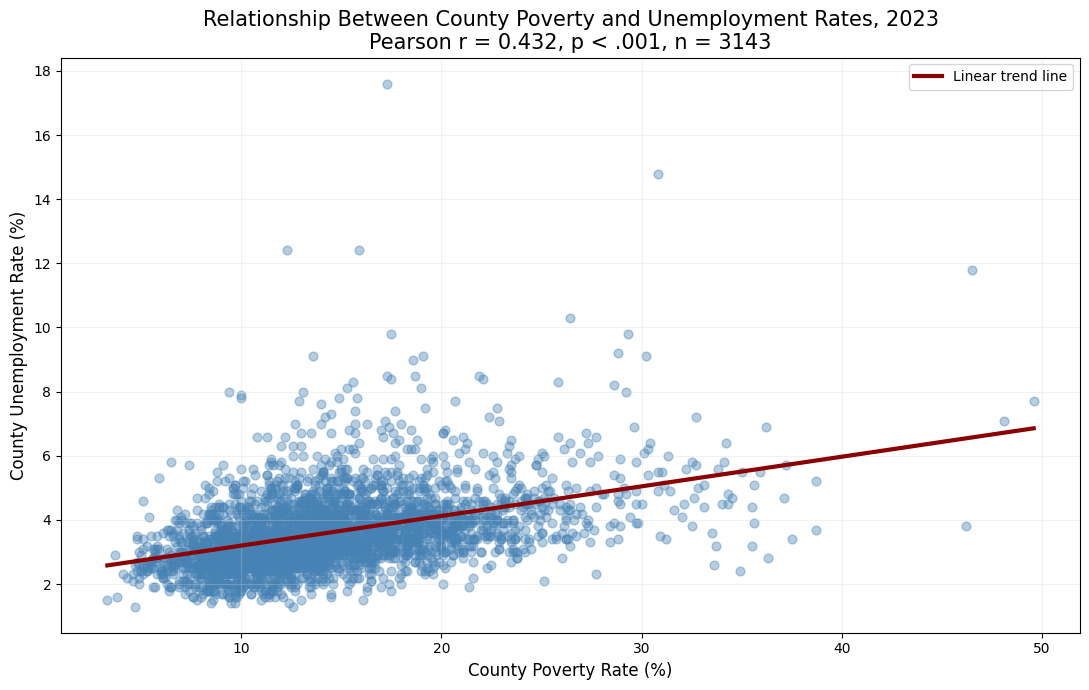

In [154]:
plt.figure(figsize=(11, 7))

sns.regplot(
    data=county,
    x="poverty_rate_2023",
    y="unemployment_rate_2023",
    ci=None,
    scatter_kws={
        "color": "steelblue",
        "alpha": 0.4,
        "s": 40
    },
    line_kws={
        "color": "darkred",
        "linewidth": 3,
        "label": "Linear trend line"
    }
)

plt.xlabel("County Poverty Rate (%)", fontsize=12)
plt.ylabel("County Unemployment Rate (%)", fontsize=12)

plt.title(
    "Relationship Between County Poverty and Unemployment Rates, 2023\n"
    f"Pearson r = {correlation:.3f}, p < .001, n = {len(county)}",
    fontsize=15
)

plt.legend()
plt.grid(color="lightgray", alpha=0.3)
plt.tight_layout()
plt.show()

### Visual observations

- Most counties are concentrated between poverty rates of approximately 5% to 25% and unemployment rates of approximately 1.5% to 6%.

- The dark-red line of best fit slopes upward, showing a positive linear relationship. This means that counties with higher poverty rates generally tend to have higher unemployment rates.

- However, the observations do not fall directly on the line. There are also several counties with unusually high poverty or unemployment rates. This spread and the presence of outliers show that poverty rate alone does not completely explain differences in county unemployment.

### Results and conclusion

- Across the 3,143 counties in the dataset, the Pearson correlation coefficient between poverty and unemployment rates was approximately **0.432**. This shows a moderate positive linear relationship, meaning counties with higher poverty rates generally tended to have higher unemployment rates in 2023.

- The p-value was approximately **7.23 × 10⁻¹⁴³**, which is much smaller than the significance level of 0.05. Therefore, we reject the null hypothesis and conclude that there is a statistically significant linear relationship between poverty and unemployment rates.

- The graph shows an upward trend, which supports the positive correlation between poverty and unemployment rates. However, the points are spread out, and several outliers are present. This suggests that other factors besides poverty may also affect county unemployment rates.

- Since this analysis uses observational data, the results show correlation rather than causation. We cannot conclude that higher poverty directly causes higher unemployment because other factors, such as education, household income, local industries, and employment opportunities, may affect both variables.

# Rural vs. Urban County Unemployment Rates

#### Research Question: Do rural and urban counties U.S. counties have singinifcantly different mean unemployment rates in 2023?


We use a two sample t-test because we want to compare the mean unemployment rates of two independent groups: rural and urban U.S. counties. 
The test helps us determine whether the difference between the two sample means is statistically significant. 

We use Welch's t-test which does not assume that the two groups share the same variance.

We use a significane level of alpha = 0.05 


**Null Hypothesis**: There is no difference in the population mean unemployment rates between rural and urban counties.  

**Alternate Hypothesis**: There is a difference in the population mean unemployment rates between rural and urban counties.  


In [155]:
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
import pandas as pd


df = pd.read_csv("county_aggregated_2023.csv")
df = df.dropna(subset = ["unemployment_rate_2023","rural_urban_continuum_code_2023"])
urban  = df.loc[df["rural_urban_continuum_code_2023"].between(1,3), "unemployment_rate_2023"]
rural = df.loc[df["rural_urban_continuum_code_2023"].between(4,9), "unemployment_rate_2023"]

t_stat, p_value = ttest_ind(urban, rural, equal_var= False)

print("P-value:", p_value)
print("T-statistic:", t_stat)

if p_value < 0.05:
    print("We reject the null hypothesis.")
else: 
    print("We fail to reject the null hypothesis.")


P-value: 5.279664470994017e-07
T-statistic: -5.027670736010916
We reject the null hypothesis.


#### Visualization

We use a barchart and boxplot to compare unemployment rates between rural and urban counties in 2023.
Each visualization provides a different perspective on the data. 

The bar chart makes a comparison between the mean unemployment rates of rural and urban counties, allowing us to
examine the difference in average unemployment rates between the two groups.

The boxplot compares the distrubtion of the two groups, while also taking into account the median, variability, and
potential outliers in unemployment rates for rural and urban counties. 

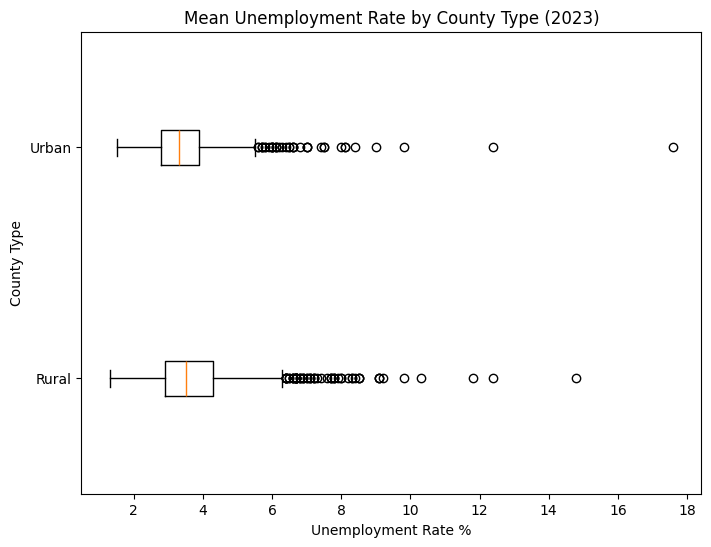

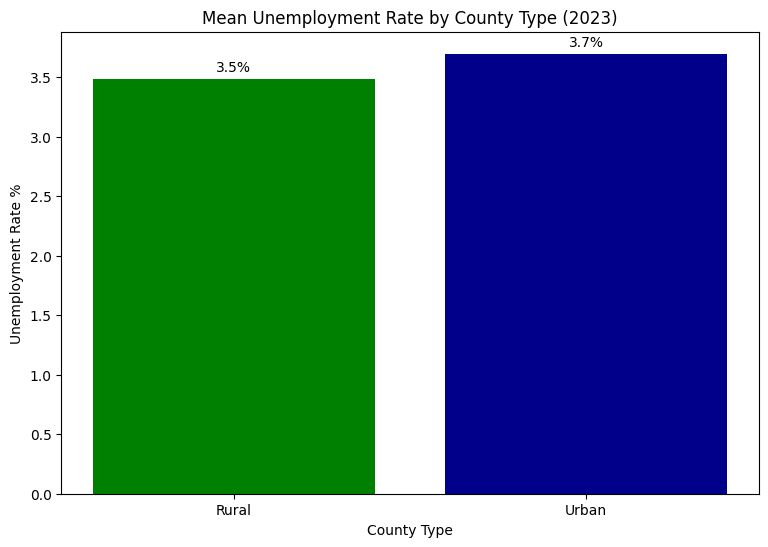

In [156]:
plt.figure(figsize=(8,6))
average_county = [urban.mean(), rural.mean()]
box_plot = plt.boxplot([rural, urban], tick_labels = ["Rural", "Urban"], vert = False)
plt.ylabel("County Type")
plt.xlabel("Unemployment Rate %")
plt.title("Mean Unemployment Rate by County Type (2023)")
plt.show()


plt.figure(figsize=(9,6))
bars = plt.bar(["Rural", "Urban"], average_county, color = ['green', 'darkblue'])
plt.bar_label(bars, fmt= '%.1f%%', padding = 3)
plt.xlabel("County Type")
plt.ylabel("Unemployment Rate %")
plt.title("Mean Unemployment Rate by County Type (2023)")
plt.show()



**Results and Conclusion**

The bar chart shows that the mean unemployment rate for rural counties is 3.5%, while the mean unemployment rate for urban counties is 3.7% in 2023.
This shows that urban counties had a higher unemployment rate than rural counties. 

The boxplot provides us with additional information on the distribution of unemployment rates across both groups. 
The median unemployment rate appears to be slightly higher for rural counties than urban counties, despite the bar chart showing a higher
mean for urban counties. Both groups have many outliers, suggesting that some counties may have higher unemployment than others.

A two-sample t-test was conducted to determine the difference in mean unemployment rates between rural and urban counties. 
The results show that the t-test produced a p-value of  5.27966 × 10⁻⁷, which is less than the significance level of 0.05.
Therefore, we reject the null hypothesis. 

Overall, the results indicate that there is enough evidence to conclude that the mean unemployment rates differ between rural
and urban U.S. counties in 2023, as the p-value is less than the significance value of 0.05. 

However, the difference between both county types is relatively small, at only 0.2 percentage points. The boxplot also highlights some potential outliers, which indicates that some rural and urban counties experience far higher unemployment rates than other counties.  



## Rural vs. Urban County High Poverty

### Research question

Are rural counties more likely to be high-poverty counties than urban counties in 2023?

The USDA defines a high-poverty county as a county where 20% or more of residents live in poverty. We label counties with a Rural-Urban Continuum Code of 1-3 as urban and 4-9 as rural.

### Statistical method

We use a chi-square test of independence because both variables are categorical (rural/urban and high-poverty/not high-poverty). The test compares the observed counts of counties in each group with the counts we would expect if the two variables were not related. significance level of alpha = 0.05.

**Null hypothesis** : Whether a county is rural or urban is independent of whether it is a high-poverty county.

**Alternative hypothesis** : Whether a county is rural or urban is correlated with whether it is a high-poverty county.

In [12]:
from scipy.stats import chi2_contingency

county["area"] = county["rural_urban_continuum_code_2023"].apply(lambda code: "Urban" if code <= 3 else "Rural")
county["high_poverty"] = county["poverty_rate_2023"] >= 20

observed = pd.crosstab(county["area"], county["high_poverty"])

chi2_results = chi2_contingency(observed)

chi2_statistic = chi2_results[0]
chi2_p_value = chi2_results[1]

print("Chi-square statistic:", chi2_statistic)
print("P-value:", chi2_p_value)

if chi2_p_value < 0.05:
    print("Reject the null hypothesis. ")
else:
    print("Fail to reject the null hypothesis.")

Chi-square statistic: 81.01059766534513
P-value: 2.245104597790872e-19
Reject the null hypothesis. 


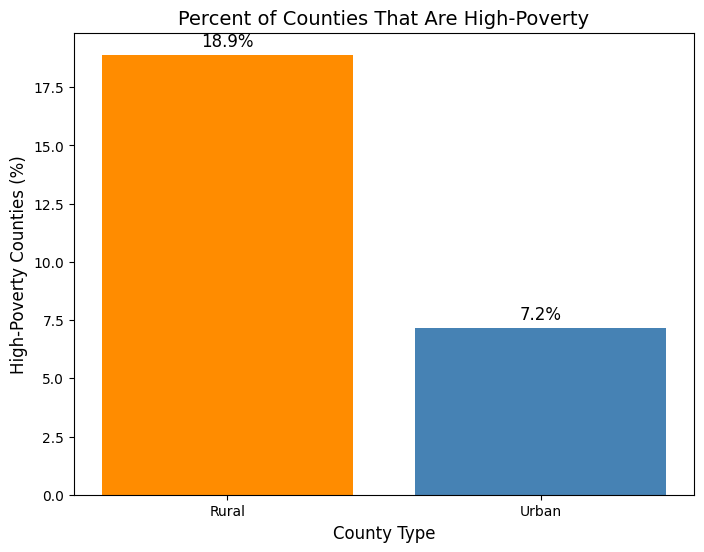

In [13]:
high_poverty_pct = county.groupby("area")["high_poverty"].mean() * 100

plt.figure(figsize=(8, 6))
bars = plt.bar(high_poverty_pct.index, high_poverty_pct, color=["darkorange", "steelblue"])
plt.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=12)

plt.xlabel("County Type", fontsize=12)
plt.ylabel("High-Poverty Counties (%)", fontsize=12)
plt.title(
    f"Percent of Counties That Are High-Poverty",
    fontsize=14
)
plt.show()

### Results and conclusion

- The chi-square test gave a statistic of about **81.01** and a p-value of about **2.25 × 10⁻¹⁹**, which is less than 0.05. Therefore, we reject the null hypothesis and conclude that being rural or urban is correlated with being a high-poverty county.

- About 18.9% of rural counties were high-poverty counties, compared to only 7.2% of urban counties.

- This test only shows correlation, not causation.